[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/philippe-amuzuga/Meca-IA_Ed2026/blob/main/meca-ia/C15/E15-2_Marquages_8x8_CORRIGE.ipynb)

# Lecture d'un marquage de pièce par caméra

## Le contexte

Une pièce est marquée d'un chiffre par micropercussion : une matrice de 5 colonnes sur 7 lignes d'emplacements, dont certains reçoivent un point. Une caméra de lecture, de 8 sur 8 pixels, doit relire ce chiffre pour tracer la pièce. Le chiffre n'est jamais exactement centré, ni droit, ni éclairé de la même façon ; certains points sont mal percutés et le capteur ajoute du bruit. Un échantillon de 4 000 marquages a été photographié et lu par un opérateur, à raison de 400 par chiffre.

La grandeur à prédire est une catégorie parmi dix, de 0 à 9 : c'est un problème de classification.

Défi : prédire `chiffre` et obtenir une exactitude supérieure à celle du modèle de départ sur la base de test. Ce modèle de départ est le réseau dense de scikit-learn, aux réglages par défaut ; il atteint une exactitude de 0,83. À vous de faire mieux avec un réseau convolutif de Keras. La règle de découpage est fixée plus bas. La base de test sert à mesurer, jamais à apprendre ni à régler.

## Les données

Fichier `MecaIA-Marquages_8x8.xlsx`, dans le dossier `donnees` du dépôt : 4 000 images, 65 colonnes. Une ligne est l'image 8 × 8 d'un marquage vu par la caméra de lecture.

| Colonne | Signification | Unité |
|---|---|---|
| `p00` à `p63` | pixels de l'image, lus ligne par ligne : `p00` en haut à gauche, `p07` en haut à droite, `p63` en bas à droite | niveau de gris, 0 noir et 255 blanc |
| `chiffre` | cible : chiffre marqué sur la pièce | 0 à 9 |

Origine : jeu simulé, rendu d'un chiffre en matrice de points 5 × 7, avec une position, une rotation, une inclinaison, un pas de matrice et un éclairage qui varient d'une image à l'autre, des points manquants, le bruit du capteur et quelques taches parasites. Il enseigne une méthode, et aucune conclusion de traçabilité n'en découle.

### Étape 1 : charger le fichier et regarder sa forme

On lit le classeur, puis on vérifie ses dimensions, ses cases vides et la répartition des classes avant toute modélisation : la forme d'un fichier se lit sur le fichier entier. Le dossier des données est cherché depuis le dossier du notebook, puis depuis un clone du dépôt ; ouvert seul, par exemple dans Colab, le notebook télécharge une fois le jeu depuis le dépôt public.

In [1]:
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import set_config

set_config(display="text")
GRAINE = 42
FICHIER = "MecaIA-Marquages_8x8.xlsx"
URL_JEU = "https://raw.githubusercontent.com/philippe-amuzuga/Meca-IA_Ed2026/main/donnees/MecaIA-Marquages_8x8.xlsx"

# Le dossier `donnees` du dépôt, cherché depuis le dossier du notebook, puis depuis un clone.
candidats = [Path("..", "..", "donnees"), Path("Meca-IA_Ed2026", "donnees")]
dossier = next((d for d in candidats if (d / FICHIER).is_file()), None)
if dossier is None:
    # Notebook ouvert seul (Colab) : copie unique du jeu depuis le dépôt public.
    dossier = Path("donnees")
    dossier.mkdir(exist_ok=True)
    try:
        urllib.request.urlretrieve(URL_JEU, dossier / FICHIER)
    except OSError as erreur:
        raise FileNotFoundError(
            "Jeu introuvable : clonez le dépôt, ou vérifiez la connexion pour le télécharger.") from erreur
df = pd.read_excel(dossier / FICHIER)

cible = "chiffre"
pixels = [f"p{k:02d}" for k in range(64)]
print("dimensions :", df.shape)
print("cases vides :", int(df.isna().sum().sum()))
print("images par chiffre :", df[cible].value_counts().sort_index().tolist())
df[pixels[:5] + [cible]].head(3)

dimensions : (4000, 65)
cases vides : 0
images par chiffre : [400, 400, 400, 400, 400, 400, 400, 400, 400, 400]


,p00,p01,p02,p03,p04,chiffre
0,2,0,3,0,0,8
1,189,174,127,205,131,7
2,0,24,46,0,39,2


Lecture du résultat : 4 000 images, 65 colonnes, aucune case vide, et exactement autant d'images pour chaque chiffre : le hasard donne une exactitude de 10 %, et une exactitude se lit sans précaution particulière sur la répartition.

### Préparation du dépôt (Colab)

Ouvert seul dans Colab, ce notebook ne voit pas le dossier `donnees/` du dépôt. La cellule suivante ne télécharge rien : elle cherche ce dossier (à deux dossiers au-dessus du notebook, à côté de lui ou dans un clone nommé `Meca-IA_Ed2026`), vérifie la présence du classeur du défi et, sur Colab, liste ce qui manque. Pour le fournir, ouvrez le panneau des fichiers de Colab, créez le dossier `donnees` à la racine de l'espace de travail et téléversez-y le classeur listé, pris dans le dépôt.

In [ ]:
# Préparation du dépôt (utile sur Colab) : cette cellule ne télécharge rien.
import os
from pathlib import Path

JEUX_LUS = ["MecaIA-Marquages_8x8.xlsx"]                  # le classeur lu par ce notebook


def chercher(dossier):
    """Le dossier du dépôt cherché depuis le notebook, puis depuis un clone ; None s'il est introuvable."""
    for base in (Path("..", ".."), Path("."), Path("Meca-IA_Ed2026")):
        if (base / dossier).is_dir():
            return base / dossier
    return None


donnees = chercher("donnees")
manque = [f"donnees/{nom}" for nom in JEUX_LUS if donnees is None or not (donnees / nom).is_file()]
if manque and "COLAB_RELEASE_TAG" in os.environ:          # variable posée par Colab
    print("À téléverser dans l'espace de travail de Colab, panneau des fichiers :")
    print("\n".join("  " + nom for nom in manque))


### Reproductibilité

Un réseau de neurones part de poids tirés au hasard et lit ses exemples dans un ordre tiré au hasard. La cellule suivante fixe toutes les graines, demande des opérations de calcul déterministes, impose un seul fil de calcul et un jeu d'instructions donné. Avec elle, deux exécutions du notebook sur le même ordinateur donnent les mêmes poids et le même score. Chaque cellule qui construit un réseau rappelle la graine dans sa première ligne : on peut la rejouer seule sans changer le résultat. Sur un autre ordinateur, ou sur un processeur qui mêle deux types de cœurs, les arrondis peuvent différer et le score changer à la troisième décimale.

In [2]:
# Réseaux de neurones : mêmes résultats à chaque exécution.
# À placer après la cellule de lecture (qui définit GRAINE),
# avant tout usage de TensorFlow.
import os

# Lues à l'import de TensorFlow : journal réduit, oneDNN limité
# au produit matriciel, jeu d'instructions fixé.
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["ONEDNN_MAX_CPU_ISA"] = "AVX2"

import numpy as np
import tensorflow as tf
import keras

# Graines, opérations déterministes et un seul fil de calcul.
keras.utils.set_random_seed(GRAINE)
tf.config.experimental.enable_op_determinism()
tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.threading.set_inter_op_parallelism_threads(1)

print("TensorFlow", tf.__version__, "| Keras", keras.__version__,
      "| NumPy", np.__version__)

TensorFlow 2.21.0 | Keras 3.15.1 | NumPy 2.4.6


### Étape 2 : mettre le test de côté

Un quart des images est mis de côté avant tout apprentissage, tout réglage et toute comparaison avec la cible. Le tirage est stratifié sur le chiffre, pour que chaque chiffre soit présent en proportion identique des deux côtés. La graine 42 fixe le tirage : chacun obtient la même base de test, et les scores se comparent. Dans l'apprentissage restant, un cinquième est réservé à la validation : il servira à comparer les réseaux et à décider quand arrêter l'entraînement, jamais le test.

In [3]:
from sklearn.model_selection import train_test_split

X = df[pixels]
y = df[cible]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=GRAINE, stratify=y)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=GRAINE, stratify=y_train)
print("apprentissage :", len(X_fit), "images")
print("validation :", len(X_val), "images")
print("test :", len(X_test), "images")

apprentissage : 2400 images
validation : 600 images
test : 1000 images


### Étape 3 : regarder les images de l'apprentissage

La figure montre quatre images tirées au hasard de l'apprentissage pour chaque chiffre, un chiffre par colonne. Le tirage ne touche que `X_train`.

niveau de gris moyen au centre : 105, sur le pourtour : 37


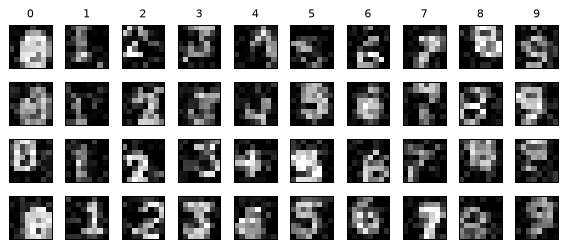

In [4]:
rng = np.random.default_rng(GRAINE)
fig, axes = plt.subplots(4, 10, figsize=(6.4, 2.9))
for j in range(10):
    for i, position in enumerate(rng.choice(X_train.index[y_train == j], 4, replace=False)):
        axes[i, j].imshow(X_train.loc[position].to_numpy().reshape(8, 8), cmap="gray", vmin=0, vmax=255)
        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])
    axes[0, j].set_title(str(j), fontsize=9)
plt.tight_layout()
plt.show()
moyenne_image = X_train.mean().to_numpy().reshape(8, 8)
print(f"niveau de gris moyen au centre : {moyenne_image[2:6, 2:6].mean():.0f}, sur le pourtour : {np.r_[moyenne_image[0], moyenne_image[-1], moyenne_image[:, 0], moyenne_image[:, -1]].mean():.0f}")

Lecture du résultat : un chiffre de 5 sur 7 points, vu en 8 sur 8 pixels, devient une tache : chaque point percuté couvre à peine un pixel, et les points voisins se fondent. D'une image à l'autre, le chiffre se décale de plusieurs pixels, penche, et change d'éclairage. Le niveau de gris moyen est de 105 au centre et plus bas sur le pourtour : le chiffre est souvent proche du centre, mais pas toujours. Un modèle qui apprend « tel pixel est allumé pour tel chiffre » est fragile ; un modèle qui reconnaît un motif où qu'il soit, c'est la promesse de la convolution.

### Étape 4 : construire le modèle de départ

Le modèle de départ est le réseau dense de scikit-learn, aux réglages par défaut : une couche cachée de 100 neurones, 200 époques au plus. Un pipeline ramène d'abord chaque pixel à une moyenne nulle et à un écart type de 1, puis ajuste le réseau sur `X_train` seul.

In [5]:
# Solution :
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

modele = make_pipeline(StandardScaler(), MLPClassifier(random_state=GRAINE))
modele.fit(X_train, y_train)
# Fin de la solution

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('mlpclassifier', MLPClassifier(random_state=42))])

### Étape 5 : mesurer sur la base de test

Le modèle prédit les images qu'il n'a jamais vues. Deux indicateurs sont lus : l'exactitude, part des images bien classées, et le F-score macro, moyenne des F-scores de chaque chiffre. Un témoin sans apprentissage, qui répond toujours le même chiffre, donne le point de comparaison le plus bas.

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

y_pred = modele.predict(X_test)
score_depart = accuracy_score(y_test, y_pred)
temoin = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"exactitude : {score_depart:.3f}")
print(f"F-score macro : {f1_score(y_test, y_pred, average='macro'):.3f}")
print(f"exactitude du témoin (toujours le même chiffre) : {accuracy_score(y_test, temoin.predict(X_test)):.3f}")
print(f"époques effectuées : {modele[-1].n_iter_} sur {modele[-1].max_iter} permises")

exactitude : 0.833
F-score macro : 0.831
exactitude du témoin (toujours le même chiffre) : 0.100
époques effectuées : 200 sur 200 permises


Lecture du résultat : l'exactitude est de 0,83 : le réseau lit correctement plus de 8 marquages sur 10, mais se trompe encore sur plus d'un sur dix. Le témoin, qui répond toujours le même chiffre, a une exactitude de 0,10. Le réseau a effectué 200 époques sur les 200 permises : il s'est arrêté faute d'époques, sans avoir convergé. C'est cette exactitude, mesurée sur des images que le modèle n'a jamais vues, que l'on a le droit d'annoncer.

## Pour aller plus loin : un réseau convolutif de Keras

Le modèle de départ de l'étape 4 reste le score de référence du défi. Les cellules suivantes montrent comment le dépasser sans regarder le test pour choisir. La première prépare des images de 8 sur 8 pour Keras, avec l'échelle apprise sur la partie d'apprentissage seule. La deuxième compare, sur la validation, un réseau dense de Keras et deux réseaux convolutifs, avec un arrêt précoce. La troisième décale d'un pixel les images de validation et compare la tenue des réseaux dense et convolutif : c'est le test de la promesse faite à l'étape 3. La quatrième lit les confusions du réseau retenu sur la validation. La dernière mesure le réseau retenu une seule fois sur le test. Les valeurs sont lues dans les sorties imprimées.

In [7]:
# Solution :
moyenne, ecart = X_fit.to_numpy().mean(), X_fit.to_numpy().std()      # une échelle commune à tous les pixels
A_fit = ((X_fit - moyenne) / ecart).to_numpy("float32").reshape(-1, 8, 8, 1)
A_val = ((X_val - moyenne) / ecart).to_numpy("float32").reshape(-1, 8, 8, 1)
t_fit, t_val = y_fit.to_numpy(), y_val.to_numpy()
print("images préparées :", A_fit.shape, A_val.shape)
# Fin de la solution

images préparées : (2400, 8, 8, 1) (600, 8, 8, 1)


In [8]:
# Solution :
def reseau(nom):
    keras.utils.set_random_seed(GRAINE)                     # graine rappelée : la cellule se rejoue seule
    if nom == "dense 128-64":
        couches = [keras.layers.Flatten(), keras.layers.Dense(128, activation="relu"), keras.layers.Dropout(0.2),
                   keras.layers.Dense(64, activation="relu")]
    elif nom == "convolution 32-64":
        couches = [keras.layers.Conv2D(32, 3, activation="relu"), keras.layers.Conv2D(64, 3, activation="relu"),
                   keras.layers.MaxPooling2D(), keras.layers.Flatten(), keras.layers.Dense(64, activation="relu"),
                   keras.layers.Dropout(0.2)]
    else:                                                    # convolution rembourrée 32-64
        couches = [keras.layers.Conv2D(32, 3, padding="same", activation="relu"), keras.layers.MaxPooling2D(),
                   keras.layers.Conv2D(64, 3, padding="same", activation="relu"), keras.layers.MaxPooling2D(),
                   keras.layers.Flatten(), keras.layers.Dense(64, activation="relu"), keras.layers.Dropout(0.3)]
    modele_keras = keras.Sequential([keras.Input(shape=(8, 8, 1))] + couches + [keras.layers.Dense(10, activation="softmax")])
    modele_keras.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="sparse_categorical_crossentropy",
                         metrics=["accuracy"])
    return modele_keras


noms = ["dense 128-64", "convolution 32-64", "convolution rembourrée 32-64"]
reseaux, histoires, notes_val = {}, {}, {}
for nom in noms:
    reseaux[nom] = reseau(nom)
    arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    histoires[nom] = reseaux[nom].fit(A_fit, t_fit, validation_data=(A_val, t_val), epochs=300, batch_size=32,
                                      callbacks=[arret], verbose=0)
    notes_val[nom] = accuracy_score(t_val, reseaux[nom].predict(A_val, verbose=0).argmax(axis=1))
    print(f"{nom} : {reseaux[nom].count_params()} paramètres, {len(histoires[nom].history['loss'])} époques, "
          f"exactitude de validation {notes_val[nom]:.3f}")
nom_retenu = max(notes_val, key=notes_val.get)
print("réseau retenu par la validation :", nom_retenu)
depart_val = make_pipeline(StandardScaler(), MLPClassifier(random_state=GRAINE)).fit(X_fit, y_fit)
note_depart = accuracy_score(y_val, depart_val.predict(X_val))
print(f"réseau de scikit-learn par défaut : exactitude de validation {note_depart:.3f}")
# Fin de la solution

dense 128-64 : 17226 paramètres, 44 époques, exactitude de validation 0.840
convolution 32-64 : 35914 paramètres, 28 époques, exactitude de validation 0.900
convolution rembourrée 32-64 : 35914 paramètres, 27 époques, exactitude de validation 0.908
réseau retenu par la validation : convolution rembourrée 32-64
réseau de scikit-learn par défaut : exactitude de validation 0.803


In [9]:
# Solution :
def decaler(images, pixels_a_droite):
    """Décale chaque image vers la droite, le bord libéré est rempli par le niveau de fond de l'image."""
    fond = images.min(axis=(1, 2, 3), keepdims=True)
    decalees = np.broadcast_to(fond, images.shape).copy()
    decalees[:, :, pixels_a_droite:] = images[:, :, :images.shape[2] - pixels_a_droite]
    return decalees


A_val_decale = decaler(A_val, 1)
print("exactitude de validation, images décalées d'un pixel vers la droite :")
tenue = {}
for nom in ["dense 128-64", nom_retenu]:
    tenue[nom] = accuracy_score(t_val, reseaux[nom].predict(A_val_decale, verbose=0).argmax(axis=1))
    print(f"  {nom} : {tenue[nom]:.3f} (non décalées {notes_val[nom]:.3f})")
# Fin de la solution

exactitude de validation, images décalées d'un pixel vers la droite :
  dense 128-64 : 0.702 (non décalées 0.840)
  convolution rembourrée 32-64 : 0.783 (non décalées 0.908)


In [10]:
# Solution :
from sklearn.metrics import confusion_matrix

prediction_val = reseaux[nom_retenu].predict(A_val, verbose=0).argmax(axis=1)
matrice = confusion_matrix(t_val, prediction_val)
hors_diagonale = [(matrice[i, j], i, j) for i in range(10) for j in range(10) if i != j]
confusions = sorted(hors_diagonale, reverse=True)[:3]
for n, vrai, lu in confusions:
    print(f"le {vrai} lu comme un {lu} : {n} fois sur {matrice[vrai].sum()}")
rappels = matrice.diagonal() / matrice.sum(axis=1)
print("chiffre le mieux lu :", int(rappels.argmax()), f"({rappels.max():.2f}), le moins bien lu :", int(rappels.argmin()), f"({rappels.min():.2f})")
# Fin de la solution

le 0 lu comme un 8 : 14 fois sur 60
le 9 lu comme un 8 : 5 fois sur 60
le 8 lu comme un 0 : 5 fois sur 60
chiffre le mieux lu : 1 (1.00), le moins bien lu : 0 (0.75)


In [11]:
# Solution :
retenu = reseaux[nom_retenu]
A_test = ((X_test - moyenne) / ecart).to_numpy("float32").reshape(-1, 8, 8, 1)
y_reseau = retenu.predict(A_test, verbose=0).argmax(axis=1)
r_reseau = accuracy_score(y_test, y_reseau)
print(f"réseau retenu ({nom_retenu}), mesuré une fois sur le test : exactitude {r_reseau:.3f}")
print(f"gain sur le modèle de départ : {r_reseau - score_depart:+.3f}")
print(f"F-score macro : {f1_score(y_test, y_reseau, average='macro'):.3f}")
# Fin de la solution

réseau retenu (convolution rembourrée 32-64), mesuré une fois sur le test : exactitude 0.922
gain sur le modèle de départ : +0.089
F-score macro : 0.921


Lecture du résultat : sur la validation, le réseau de scikit-learn par défaut atteint une exactitude de 0,80. Le réseau dense de Keras, aux entrées mises à l'échelle et arrêté tôt, atteint 0,84. Les deux réseaux convolutifs atteignent 0,90 et 0,91 : la validation retient « convolution rembourrée 32-64 ». Décalées d'un pixel, les images de validation font perdre 0,14 d'exactitude au réseau dense (de 0,84 à 0,70) et 0,12 au réseau retenu (de 0,91 à 0,78) : la convolution reconnaît un motif où qu'il soit, mais les couches denses qui la suivent lisent encore sa position, et le réseau retenu reste au-dessus du réseau dense sur des images décalées. Les trois confusions les plus fréquentes de la validation sont le 0 lu comme un 8 (14 fois sur 60), le 9 lu comme un 8 (5 fois) et le 8 lu comme un 0 (5 fois). Mesuré une seule fois sur le test, le réseau retenu atteint une exactitude de 0,92, soit 0,09 de plus que le modèle de départ.

## Le score de référence

Le score publié est l'exactitude du modèle de départ de l'étape 4 sur la base de test. L'empreinte identifie cette base de test : si la vôtre diffère, le découpage n'est pas le même et les scores ne se comparent pas.

In [12]:
import hashlib

score = accuracy_score(y_test, modele.predict(X_test))
positions = ",".join(str(i) for i in sorted(X_test.index))
print("EMPREINTE_TEST =", hashlib.sha256(positions.encode("ascii")).hexdigest())
print("SCORE_REFERENCE accuracy = %.2f" % score)

EMPREINTE_TEST = cd447db0a9c8f1df136f68d161da391ae0d203cbfc5b8efb5ba8cac608db9b6b
SCORE_REFERENCE accuracy = 0.83


## Synthèse

1. Un chiffre en matrice de points, vu en 8 sur 8 pixels, se décale, penche et change d'éclairage d'une image à l'autre : un réseau dense, qui apprend un poids par pixel, doit tout réapprendre pour chaque position.
2. Aux réglages par défaut, le réseau de scikit-learn atteint une exactitude de 0,83 sur le test ; le réseau convolutif retenu sur la validation atteint 0,92.
3. La comparaison des architectures se fait sur une validation prise dans l'apprentissage, avec un arrêt précoce qui rend les poids de la meilleure époque ; le test ne sert qu'une fois.
4. Décaler les images d'un pixel est un test de robustesse simple : le réseau dense tombe à 0,70, le réseau convolutif retenu à 0,78 ; la convolution aide, mais ne rend pas le réseau insensible à la position.
5. La graine est rappelée dans la cellule qui construit chaque réseau : on la rejoue seule sans changer le résultat.